# LLM Inference Optimization Testbed (server)

Complete usage example for the `llm_benchmark` package:

1. Install dependencies (vLLM + supporting packages)
2. Install the package from this repo
3. Run the full optimization pipeline
4. View the results table, charts, and summary

The pipeline benchmarks the HuggingFace baseline and vLLM (launched as an
OpenAI-compatible `vllm serve` subprocess): FP16, AWQ, Flash Attention, prefix
caching, speculative decoding, and the combined stack.


In [ ]:

!pip install vllm

!pip install -q accelerate requests openai aiohttp tqdm pandas matplotlib numpy nvidia-ml-py3 huggingface-hub


In [1]:
# 3) Get the repo and install the package (skips the clone if already present)
import os

REPO = "/content/llm-inference-benchmark"
if not os.path.isdir(REPO):
    !git clone https://github.com/h-sami-ullah/llm-inference-benchmark.git /content/llm-inference-benchmark

%cd /content/llm-inference-benchmark
!pip install -q -e .


Cloning into '/content/llm-inference-benchmark'...
remote: Enumerating objects: 179, done.
remote: Counting objects: 100% (179/179), done.
remote: Compressing objects: 100% (122/122), done.
remote: Total 179 (delta 98), reused 132 (delta 54), pack-reused 0 (from 0)
Receiving objects: 100% (179/179), 81.80 KiB | 2.04 MiB/s, done.
Resolving deltas: 100% (98/98), done.
/content/llm-inference-benchmark
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for llm-benchmark (pyproject.toml) ... done


In [2]:
from llm_benchmark import (
    setup_environment,
    set_seed,
    run_full_pipeline,
    display_results,
    save_results_to_file,
)

setup_environment()
set_seed(42)


In [3]:
import torch
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


GPU: Tesla T4
VRAM: 15.6 GB


In [4]:
# Run the whole benchmark pipeline (HF baseline + all vLLM optimizations)
results = run_full_pipeline()


Running HuggingFace baseline in a subprocess (isolated GPU memory)...
[Backup] Merged & saved 1 total unique results to '/content/benchmark_results_qwen_server.json'
Memory after HF baseline: allocated 0.00 GB, reserved 0.00 GB, nvml used 0.47 GB
Launching vLLM server (subprocess):
  /usr/local/bin/vllm serve Qwen/Qwen2.5-3B-Instruct --dtype float16 --max-model-len 2048 --gpu-memory-utilization 0.85 --tensor-parallel-size 1 --distributed-executor-backend uni --port 8000 --trust-remote-code --generation-config vllm
  Log file: /content/vllm_server_8000.log
Waiting for server at http://localhost:8000 (timeout 300s)...
  ...still waiting (0s elapsed)
  ...still waiting (5s elapsed)
  ...still waiting (10s elapsed)
  ...still waiting (15s elapsed)
[vllm] (APIServer pid=35841) INFO 10-31 21:06:53 [api_utils.py:347] 
[vllm] (APIServer pid=35841) INFO 10-31 21:06:53 [api_utils.py:347]        █     █     █▄   ▄█
[vllm] (APIServer pid=35841) INFO 10-31 21:06:53 [api_utils.py:347]  ▄▄ ▄█ █     █

In [8]:
save_results_to_file(results)
display_results(results)


[Backup] Merged & saved 7 total unique results to '/content/benchmark_results_qwen_server.json'


,ttft_ms,tps,tpm,memory_gb,total_tokens,total_time_s
name,,,,,,
HF Baseline,74.4,72.6,4358,7.11,454,6.26
vLLM Server (FP16),78.3,120.6,7237,13.36,458,3.80
vLLM Server + AWQ,43.4,271.8,16306,12.70,442,1.63
vLLM Server + AWQ + Flash,39.5,237.3,14236,12.70,768,3.24
Prefix Cache (warm),55.3,371.2,22274,14.27,640,1.72
vLLM Server + AWQ + Spec,312.0,98.1,5883,14.34,442,4.51
Combined Stack,320.9,102.7,6160,14.84,447,4.35


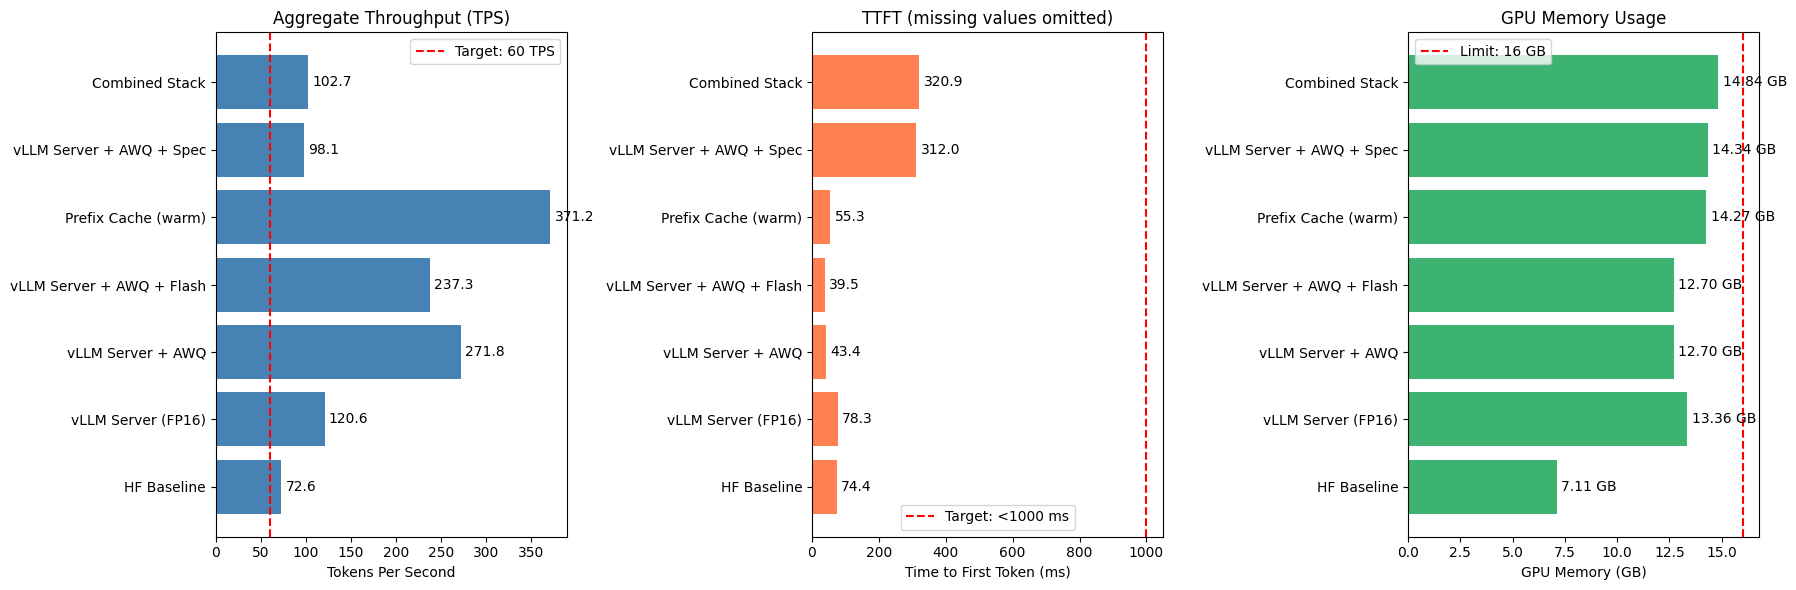

In [11]:
# Visualization
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

names = [r.name for r in results]
tps_values = [r.tps for r in results]
ttft_values = [r.ttft_ms if r.ttft_ms is not None else np.nan for r in results]
memory_values = [r.memory_gb for r in results]

# Subplot 1: TPS
bars0 = axes[0].barh(names, tps_values, color="steelblue")
axes[0].axvline(x=60, color="red", linestyle="--", label="Target: 60 TPS")
axes[0].set_xlabel("Tokens Per Second")
axes[0].set_title("Aggregate Throughput (TPS)")
axes[0].legend()
axes[0].bar_label(bars0, fmt="%.1f", padding=3)

# Subplot 2: TTFT
bars1 = axes[1].barh(names, ttft_values, color="coral")
axes[1].axvline(x=1000, color="red", linestyle="--", label="Target: <1000 ms")
axes[1].set_xlabel("Time to First Token (ms)")
axes[1].set_title("TTFT (missing values omitted)")
axes[1].legend()
axes[1].bar_label(bars1, fmt="%.1f", padding=3)

# Subplot 3: Memory
bars2 = axes[2].barh(names, memory_values, color="mediumseagreen")
axes[2].axvline(x=16, color="red", linestyle="--", label="Limit: 16 GB")
axes[2].set_xlabel("GPU Memory (GB)")
axes[2].set_title("GPU Memory Usage")
axes[2].legend()
axes[2].bar_label(bars2, fmt="%.2f GB", padding=3)

plt.tight_layout()
plt.show()

In [12]:
# Final summary
from llm_benchmark import format_ttft

baseline = next((r for r in results if r.name == "HF Baseline"), None)
final = next((r for r in results if r.name == "Combined Stack"), None)

if baseline is None or final is None:
    print("Could not find both HF Baseline and Combined Stack results.")
else:
    print("\n" + "=" * 60)
    print("FINAL IMPROVEMENT SUMMARY")
    print("=" * 60)
    print("\nBaseline (Hugging Face) -> Combined Stack:")
    print(f"  TPS:    {baseline.tps:.1f} -> {final.tps:.1f} ({final.tps / baseline.tps:.2f}x)")
    print(f"  TPM:    {baseline.tpm:.0f} -> {final.tpm:.0f}")
    print(f"  TTFT:   {format_ttft(baseline.ttft_ms)} -> {format_ttft(final.ttft_ms)}")
    print(f"  Memory: {baseline.memory_gb:.2f} GB -> {final.memory_gb:.2f} GB")

    print("\nTargets achieved:")
    if final.ttft_ms is None:
        print("  TTFT < 1000 ms: NOT MEASURED")
    else:
        print(f"  TTFT < 1000 ms: {'YES' if final.ttft_ms < 1000 else 'NO'}")
    print(f"  TPS > 60:       {'YES' if final.tps > 60 else 'NO'}")



FINAL IMPROVEMENT SUMMARY

Baseline (Hugging Face) -> Combined Stack:
  TPS:    72.6 -> 102.7 (1.41x)
  TPM:    4358 -> 6160
  TTFT:   74.4 ms -> 320.9 ms
  Memory: 7.11 GB -> 14.84 GB

Targets achieved:
  TTFT < 1000 ms: YES
  TPS > 60:       YES


## Other ways to use the package

Start and benchmark a single server manually:

```python
from llm_benchmark import start_vllm_server, wait_for_server, stop_server, benchmark_server

proc = start_vllm_server("Qwen/Qwen2.5-3B-Instruct", quantization="awq")
wait_for_server(log_path=proc.log_path)
r = benchmark_server(8000, ["Explain quantum computing in one sentence."], name="AWQ")
stop_server(proc)
```

Or run vLLM's built-in benchmark against a live server:

```bash
vllm serve Qwen/Qwen2.5-3B-Instruct

vllm bench serve --backend openai --endpoint /v1/completions \
  --model Qwen/Qwen2.5-3B-Instruct --dataset-name random \
  --random-input-len 1024 --random-output-len 256 --num-prompts 100
```
